# FlashHAR-X: Subject-Generalizable Human Activity Recognition with Custom FlashAttention

**College capstone | real UCI HAR recordings | RTX 5070 Ti on WSL Ubuntu | no synthetic training records**

**Research question:** Can a compact multiscale sensor Transformer generalize to **unseen people** while using a fully differentiable **custom Triton FlashAttention-style kernel**? Separate predictive quality from GPU efficiency; they are different hypotheses.

- **Real dataset:** [UCI HAR Using Smartphones](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones), 30 volunteers; 6 actions, 9 inertial channels, 128 readings/window at 50Hz. Preserve official **subject-disjoint** train/test protocol.
- **Target:** >90% official holdout accuracy (minimum), >97% (stretch); **not guaranteed**. No test-set hyperparameter tuning.
- **Compare:** SVM on supplied 561 engineered features, CNN-only, multiscale Transformer with PyTorch SDPA, identical architecture with custom Triton FlashAttention.
- **Kernel:** forward/backward written in `flash_attention_triton.py`; validates against PyTorch SDPA, never substitutes SDPA on Triton failure. Its purpose is memory-bounded attention; it is **not guaranteed faster** than PyTorch's production kernels at length 128.
- **Novelty as a student project, not a claim of a new scientific method:** reproducible subject-independent multiscale recognition + custom fused attention kernel + robustness and ablation reporting.

Read `README.md` first. The kernel runs **only on CUDA Linux**, not CPU/Windows-native. All data download uses authentic UCI archives.

## 0. Environment (run once in a WSL terminal)

```bash
cd ~/projects/FlashHAR_X              # copy this entire folder here
python3.11 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
pip install torch==2.9.0 --index-url https://download.pytorch.org/whl/cu128
pip install -r requirements.txt
python -m ipykernel install --user --name flashhar-x --display-name "Python (FlashHAR-X)"
jupyter lab
```

Select the **Python (FlashHAR-X)** kernel. Check `nvidia-smi` in WSL. Do not separately install a conflicting Triton build: compatible Triton is a dependency of the CUDA PyTorch package. Requires CUDA-compatible NVIDIA driver and working WSL GPU passthrough.

In [1]:
import os, sys, json, random, platform, time, copy
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.svm import SVC
from tqdm.auto import tqdm
from flashhar_model import FlashHARX, augment_raw

ROOT = Path.cwd()
DATA_DIR, OUTPUT_DIR = ROOT / 'data', ROOT / 'artifacts'
DATA_DIR.mkdir(exist_ok=True); OUTPUT_DIR.mkdir(exist_ok=True)
SEED = 42
EPOCHS = 45
BATCH_SIZE = 128        # change to 64 if VRAM pressure
LR = 1.2e-3
PATIENCE = 10
RUN_CNN_BASELINE = True
USE_FEATURES = True    # existing UCI hand-engineered features from the same sensor data

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

set_seed(SEED)
assert torch.cuda.is_available(), 'GPU required; run inside WSL with CUDA-enabled PyTorch.'
print('Python:',sys.version.split()[0], 'PyTorch:',torch.__version__)
print('GPU:', torch.cuda.get_device_name(0), 'compute capability:', torch.cuda.get_device_capability(0))
print('CUDA runtime:',torch.version.cuda, 'Triton:',__import__('triton').__version__)
print('CUDA free/total VRAM (GiB):', tuple(round(x/2**30,2) for x in torch.cuda.mem_get_info()))
if torch.cuda.get_device_capability(0)[0] < 8:
    raise RuntimeError('This custom kernel requires an Ampere-or-newer GPU for FP16 tl.dot.')

/home/saitej/projects/FlashHAR_X/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.15 PyTorch: 2.9.0+cu128
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU compute capability: (12, 0)
CUDA runtime: 12.8 Triton: 3.5.0
CUDA free/total VRAM (GiB): (10.77, 11.91)


## 1. Download and parse the ORIGINAL dataset

UCI's official archive contains the raw 9-channel time series (not simulated records), plus 561 precomputed signal features. This cell handles archives with an inner zip. If the UCI server is temporarily unavailable, manually obtain **UCI HAR Dataset.zip** from the linked official dataset and place it in `data/`.

In [2]:
import urllib.request, zipfile
URL = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
ARCHIVE = DATA_DIR / 'uci_har_official.zip'

def extract_dataset():
    found = list(DATA_DIR.rglob('body_acc_x_train.txt'))
    if found:
        return found[0].parent.parent.parent
    if not ARCHIVE.exists():
        print('Downloading official archive (58 MB)...')
        try: urllib.request.urlretrieve(URL, ARCHIVE)
        except Exception as exc:
            # Also handle a manually downloaded file placed in data/
            options = list(DATA_DIR.glob('*.zip'))
            if not options: raise RuntimeError('Official UCI download failed; place UCI HAR Dataset.zip into data/.') from exc
            archive_to_use = options[0]
        else: archive_to_use = ARCHIVE
    else: archive_to_use = ARCHIVE
    with zipfile.ZipFile(archive_to_use) as z: z.extractall(DATA_DIR)
    for inner in DATA_DIR.rglob('*.zip'):
        if inner.resolve() == archive_to_use.resolve(): continue
        with zipfile.ZipFile(inner) as z: z.extractall(DATA_DIR)
    found = list(DATA_DIR.rglob('body_acc_x_train.txt'))
    if not found: raise RuntimeError('Raw inertial signals not found in extracted UCI archive.')
    return found[0].parent.parent.parent

UCI_ROOT = extract_dataset()
print('Dataset root:',UCI_ROOT)
print('License: CC BY 4.0; cite DOI 10.24432/C54S4K')

Dataset root: /home/saitej/projects/FlashHAR_X/data/UCI HAR Dataset
License: CC BY 4.0; cite DOI 10.24432/C54S4K


In [3]:
CHANNELS = [f'{s}_{axis}' for s in ('body_acc','body_gyro','total_acc') for axis in 'xyz']
ACTIVITIES = ['WALKING','WALKING_UPSTAIRS','WALKING_DOWNSTAIRS','SITTING','STANDING','LAYING']

def load_partition(part):
    signal_dir = UCI_ROOT / part / 'Inertial Signals'
    channels = [np.loadtxt(signal_dir / f'{ch}_{part}.txt', dtype=np.float32) for ch in CHANNELS]
    raw = np.stack(channels, axis=1).astype(np.float32)  # [samples, 9, 128]
    engineered = np.loadtxt(UCI_ROOT / part / f'X_{part}.txt', dtype=np.float32)
    labels = np.loadtxt(UCI_ROOT / part / f'y_{part}.txt',dtype=int) - 1
    subjects = np.loadtxt(UCI_ROOT / part / f'subject_{part}.txt',dtype=int)
    assert len(raw)==len(labels)==len(subjects)==len(engineered)
    assert raw.shape[1:]==(9,128) and engineered.shape[1]==561
    return raw, engineered, labels, subjects

X_train, F_train, y_train, subject_train = load_partition('train')
X_test, F_test, y_test, subject_test = load_partition('test')
assert not (set(subject_train) & set(subject_test)), 'Official test has overlapping subjects!'
assert len(X_train)==7352 and len(X_test)==2947, 'Unexpected dataset size.'
print('Training:', X_train.shape, 'official test:', X_test.shape)
print('Train subject IDs:', sorted(set(subject_train)), '\\nTest subject IDs:', sorted(set(subject_test)))
print('Class counts:\\n',pd.Series(y_train).map(dict(enumerate(ACTIVITIES))).value_counts())

Training: (7352, 9, 128) official test: (2947, 9, 128)
Train subject IDs: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)] \nTest subject IDs: [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
Class counts:\n LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64


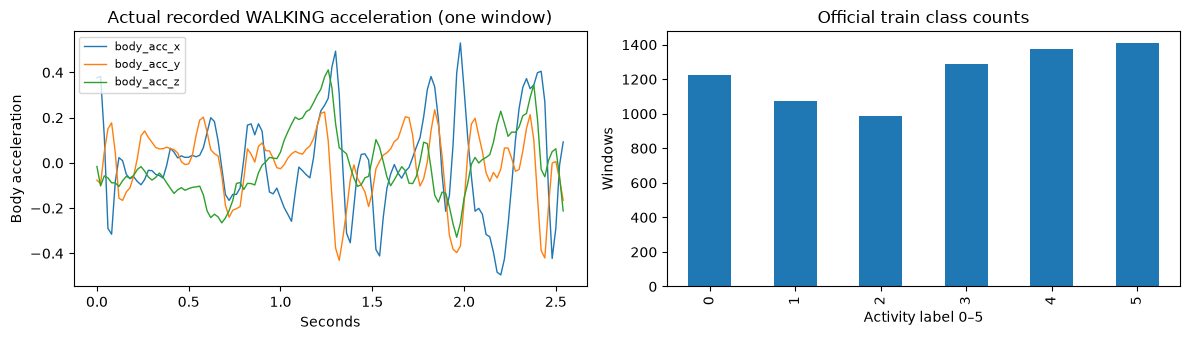

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12,3.5))
sample_i = next(i for i,v in enumerate(y_train) if v==0)
for c in range(3): axes[0].plot(np.arange(128)/50, X_train[sample_i,c], label=CHANNELS[c], linewidth=1)
axes[0].set(title='Actual recorded WALKING acceleration (one window)', xlabel='Seconds', ylabel='Body acceleration')
axes[0].legend(fontsize=8)
pd.Series(y_train).value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title='Official train class counts',xlabel='Activity label 0–5',ylabel='Windows')
plt.tight_layout(); plt.show()

## 2. Freeze the evaluation protocol **before looking at test accuracy**

Choose validation volunteers using GroupShuffleSplit **inside the official training subjects**. Never put the same person's overlapping windows in both validation and training. Fit raw-signal normalization and 561-feature scaling on training people only. Use the validation subjects to choose each model's epoch count, then **retrain on all official training people** for that fixed count. Test labels are evaluated only in §7 after all decisions are fixed.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.22, random_state=SEED)
train_idx, val_idx = next(gss.split(X_train, y_train, subject_train))
assert not (set(subject_train[train_idx]) & set(subject_train[val_idx]))
assert not (set(subject_train[val_idx]) & set(subject_test))
print('Training subjects:', sorted(set(subject_train[train_idx])))
print('Validation subjects:', sorted(set(subject_train[val_idx])))
print('Official test subjects:',len(set(subject_test)))

def fit_normalizers(raw, feat):
    mu = raw.mean(axis=(0,2),keepdims=True)
    std = raw.std(axis=(0,2),keepdims=True).clip(min=1e-5)
    scaler = StandardScaler().fit(feat)
    return mu, std, scaler

def transform_arrays(raw, feat, y, normalizers):
    mu, std, scaler = normalizers
    a = ((raw-mu)/std).astype(np.float32)
    b = scaler.transform(feat).astype(np.float32)
    return TensorDataset(torch.from_numpy(a),torch.from_numpy(b),torch.tensor(y,dtype=torch.long))

def make_loader(dataset, shuffle):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, pin_memory=True, num_workers=0)

val_norm = fit_normalizers(X_train[train_idx],F_train[train_idx])
tr_loader = make_loader(transform_arrays(X_train[train_idx],F_train[train_idx],y_train[train_idx],val_norm),True)
va_loader = make_loader(transform_arrays(X_train[val_idx],F_train[val_idx],y_train[val_idx],val_norm),False)
print('Group-disjoint windows:',len(train_idx),'train /',len(val_idx),'validation')

Training subjects: [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(26), np.int64(28), np.int64(29), np.int64(30)]
Validation subjects: [np.int64(1), np.int64(3), np.int64(15), np.int64(25), np.int64(27)]
Official test subjects: 9
Group-disjoint windows: 5551 train / 1801 validation


## 3. Verify our CUSTOM GPU kernel (forward + backward)

**Critical gate:** The file `flash_attention_triton.py` implements online-softmax tiled forward plus recomputation-based, fully custom Triton backward (dQ,dK,dV), not a reference backward and not an SDPA wrapper. Test its actual GPU behavior first. If a test fails, investigate rather than silently switching to another backend. FP16 differences from floating-point roundoff are expected.

In [8]:
from flash_attention_triton import check_correctness, flash_attention
check_correctness()

PASS N=128 D=32, forward max_abs=0.0001221; gradients within 3.5% rel L2
PASS N=128 D=64, forward max_abs=0.0001221; gradients within 3.5% rel L2
PASS N=256 D=32, forward max_abs=6.104e-05; gradients within 3.5% rel L2
PASS N=256 D=64, forward max_abs=6.104e-05; gradients within 3.5% rel L2
All custom FlashAttention forward/backward checks passed.


## 4. Train models, selecting epochs on unseen VALIDATION people

One change per comparison: PyTorch SDPA and custom Triton use identical network weights/architecture (different random starts are controlled by seed) and see identical data; any accuracy difference should be interpreted as training variation/numerical effects, **not an accuracy advantage built into FlashAttention**.

Data augmentation applies small noise/scale/dropout to the *raw branch only*, while the official engineered features remain as computed. Hence such perturbations do not constitute a true end-to-end sensor-corruption test for the fused model.


===== Epoch selection: cnn_only =====
cnn_only ep 01/45: loss=1.4233 val acc=0.8662 F1=0.8526
cnn_only ep 02/45: loss=0.4982 val acc=0.9611 F1=0.9594
cnn_only ep 03/45: loss=0.2663 val acc=0.9756 F1=0.9757
cnn_only ep 04/45: loss=0.2074 val acc=0.9767 F1=0.9770
cnn_only ep 05/45: loss=0.1959 val acc=0.9806 F1=0.9809
cnn_only ep 10/45: loss=0.1539 val acc=0.9783 F1=0.9788
cnn_only ep 11/45: loss=0.1497 val acc=0.9850 F1=0.9853
cnn_only ep 15/45: loss=0.1427 val acc=0.9839 F1=0.9842
cnn_only ep 20/45: loss=0.1426 val acc=0.9789 F1=0.9794
Early stopped; best epoch 11

===== Epoch selection: torch_sdpa =====
torch_sdpa ep 01/45: loss=1.3687 val acc=0.9417 F1=0.9339
torch_sdpa ep 02/45: loss=0.4238 val acc=0.9733 F1=0.9739
torch_sdpa ep 03/45: loss=0.2578 val acc=0.9756 F1=0.9759
torch_sdpa ep 05/45: loss=0.1883 val acc=0.9767 F1=0.9771
torch_sdpa ep 06/45: loss=0.1782 val acc=0.9800 F1=0.9804
torch_sdpa ep 07/45: loss=0.1688 val acc=0.9878 F1=0.9880
torch_sdpa ep 10/45: loss=0.1557 val ac

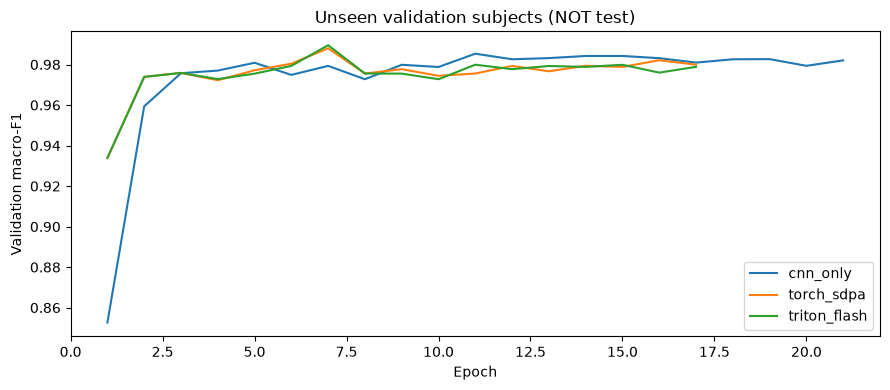

In [9]:
from contextlib import nullcontext
DEVICE = torch.device('cuda')

def amp(): return torch.autocast('cuda', dtype=torch.float16)

def validation_predictions(model, loader):
    model.eval(); ys=[]; ps=[]
    with torch.inference_mode():
        for raw,feat,target in loader:
            with amp(): pred=model(raw.to(DEVICE,non_blocking=True),feat.to(DEVICE,non_blocking=True))
            ys.append(target.numpy()); ps.append(pred.float().argmax(-1).cpu().numpy())
    return np.concatenate(ys),np.concatenate(ps)

def train_epoch(model, loader, optimizer, scheduler, scaler):
    model.train(); losses=[]
    for raw,feat,y in loader:
        raw=raw.to(DEVICE,non_blocking=True); feat=feat.to(DEVICE,non_blocking=True)
        y=y.to(DEVICE,non_blocking=True)
        raw=augment_raw(raw)
        optimizer.zero_grad(set_to_none=True)
        with amp():
            logits=model(raw,feat)
            loss=F.cross_entropy(logits.float(),y,label_smoothing=0.025)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(),1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        losses.append(float(loss.detach()))
    return float(np.mean(losses))

def fit_model(backend, seed, train_loader, valid_loader=None, epochs=EPOCHS, patience=PATIENCE):
    set_seed(seed)
    model=FlashHARX(backend=backend,use_features=USE_FEATURES).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(), lr=LR,weight_decay=0.02)
    schedule=torch.optim.lr_scheduler.OneCycleLR(optimizer,max_lr=LR,total_steps=epochs*len(train_loader),pct_start=0.1)
    scaler=torch.amp.GradScaler('cuda')
    best_score=-float('inf'); best_epoch=epochs; best_state=None; stale=0; history=[]
    for ep in range(1,epochs+1):
        start=time.perf_counter()
        loss=train_epoch(model,train_loader,optimizer,schedule,scaler)
        entry={'epoch':ep,'loss':loss,'seconds':time.perf_counter()-start}
        if valid_loader is not None:
            yt,yp=validation_predictions(model,valid_loader)
            entry['val_accuracy']=accuracy_score(yt,yp)
            entry['val_macro_f1']=f1_score(yt,yp,average='macro')
            if entry['val_macro_f1']>best_score+1e-4:
                best_score=entry['val_macro_f1']; best_epoch=ep; stale=0
                best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            else: stale+=1
        history.append(entry)
        if ep==1 or ep%5==0 or (valid_loader is not None and stale==0):
            extra=(f" val acc={entry['val_accuracy']:.4f} F1={entry['val_macro_f1']:.4f}" if valid_loader is not None else '')
            print(f'{backend} ep {ep:02d}/{epochs}: loss={loss:.4f}{extra}')
        if valid_loader is not None and stale>=patience:
            print('Early stopped; best epoch',best_epoch)
            break
    if best_state is not None: model.load_state_dict(best_state)
    return model,best_epoch,pd.DataFrame(history)

BACKENDS = ['cnn_only','torch_sdpa','triton_flash'] if RUN_CNN_BASELINE else ['torch_sdpa','triton_flash']
selected_epochs={}; val_histories={}
for backend in BACKENDS:
    print('\n===== Epoch selection:', backend,'=====')
    model,ep,log = fit_model(backend,SEED,tr_loader,va_loader)
    selected_epochs[backend]=ep; val_histories[backend]=log
    del model
    torch.cuda.empty_cache()
print('Locked, validation-selected epoch counts:',selected_epochs)
fig, ax=plt.subplots(figsize=(9,4))
for key,log in val_histories.items(): ax.plot(log['epoch'],log['val_macro_f1'],label=key)
ax.set(xlabel='Epoch',ylabel='Validation macro-F1',title='Unseen validation subjects (NOT test)')
ax.legend();plt.tight_layout();plt.show()

## 5. Classical reference baseline: RBF-SVM on the official 561 time/frequency features

The SVM uses **engineered features** supplied by the real UCI dataset. Its results are useful context, but comparisons to raw-input-only models would not be input-matched. We use all official training people, with no test selection.

In [10]:
all_mu, all_std, all_f_scaler = fit_normalizers(X_train,F_train)
from sklearn.pipeline import make_pipeline
svm=make_pipeline(StandardScaler(),SVC(C=10,gamma='scale',kernel='rbf'))
start=time.perf_counter()
svm.fit(F_train,y_train)
print('SVM fit completed in',round(time.perf_counter()-start,1),'seconds.')
# NOTE: no test prediction here. Evaluated exactly once in §7.

SVM fit completed in 1.8 seconds.


## 6. Retrain from scratch using ALL official training subjects

Refit on all 7,352 original training windows, using only the validation-selected epoch count. **Freeze** these weights and preprocessing. Do not change hyperparameters after looking at test results.

In [11]:
full_norm=fit_normalizers(X_train,F_train)
full_loader=make_loader(transform_arrays(X_train,F_train,y_train,full_norm), True)
test_loader=make_loader(transform_arrays(X_test,F_test,y_test,full_norm), False)
final_models={}
for backend in BACKENDS:
    print('\n==== Final full-data fit:',backend, 'epochs',selected_epochs[backend],'====')
    model,_,log=fit_model(backend,SEED,full_loader,None,epochs=selected_epochs[backend])
    final_models[backend]=model.eval()
    torch.save({'model':model.cpu().state_dict(),'backend':backend,
                'epochs':selected_epochs[backend],'seed':SEED,'use_features':USE_FEATURES,
                'normalization':{'raw_mean':full_norm[0],'raw_std':full_norm[1],
                                 'features_mean':full_norm[2].mean_,
                                 'features_scale':full_norm[2].scale_}},OUTPUT_DIR/f'{backend}.pt')
    model.to(DEVICE)
print('All training finalized. Test prediction is next.')


==== Final full-data fit: cnn_only epochs 11 ====
cnn_only ep 01/11: loss=0.8864
cnn_only ep 05/11: loss=0.1700
cnn_only ep 10/11: loss=0.1475

==== Final full-data fit: torch_sdpa epochs 7 ====
torch_sdpa ep 01/7: loss=0.7341
torch_sdpa ep 05/7: loss=0.1683

==== Final full-data fit: triton_flash epochs 7 ====
triton_flash ep 01/7: loss=0.7341
triton_flash ep 05/7: loss=0.1684
All training finalized. Test prediction is next.


## 7. **ONE-TIME** official held-out test evaluation

Compare accuracy, **macro-F1**, per-class errors, and confusion matrices. Do not change models or training recipes based on these results. Human baseline publication numbers are not direct wins unless protocols and inputs match.

                            model  accuracy  macro_f1
                         cnn_only    0.9684    0.9692
                       torch_sdpa    0.9630    0.9635
                     triton_flash    0.9627    0.9631
RBF-SVM (561 engineered features)    0.9549    0.9540

TEST REPORT: cnn_only
                    precision    recall  f1-score   support

           WALKING     0.9980    0.9919    0.9949       496
  WALKING_UPSTAIRS     0.9979    0.9915    0.9947       471
WALKING_DOWNSTAIRS     0.9836    1.0000    0.9917       420
           SITTING     0.9452    0.8778    0.9102       491
          STANDING     0.8989    0.9530    0.9252       532
            LAYING     0.9963    1.0000    0.9981       537

          accuracy                         0.9684      2947
         macro avg     0.9700    0.9690    0.9692      2947
      weighted avg     0.9689    0.9684    0.9683      2947


TEST REPORT: torch_sdpa
                    precision    recall  f1-score   support

           WALKING

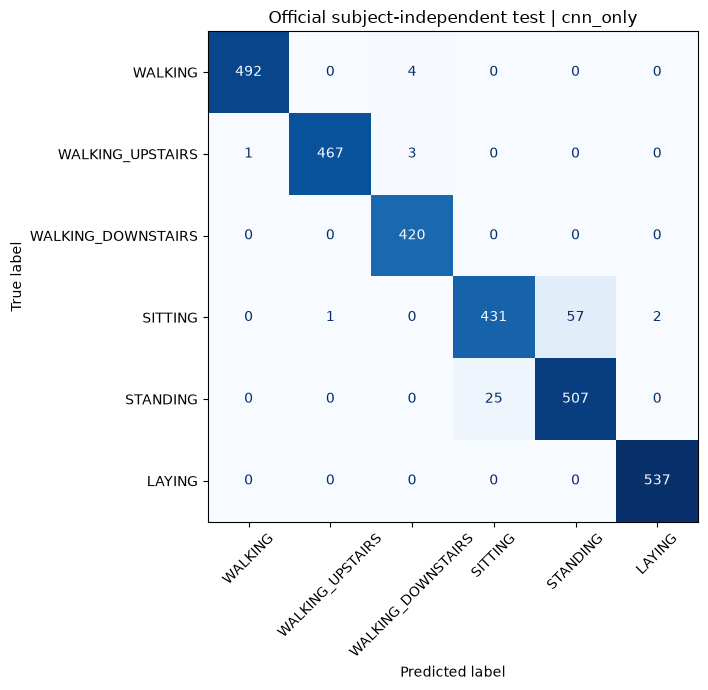

ACHIEVED: at least one neural model reached >=90% on official held-out subjects.


In [12]:
# All hyperparameters, checkpoints, and epoch counts must already be frozen.
results=[]; predictions={}
svm_pred=svm.predict(F_test)
results.append({'model':'RBF-SVM (561 engineered features)','accuracy':accuracy_score(y_test,svm_pred),
                'macro_f1':f1_score(y_test,svm_pred,average='macro')})
predictions['RBF-SVM']=svm_pred
for backend,model in final_models.items():
    y_true,y_pred=validation_predictions(model,test_loader)
    assert np.array_equal(y_true,y_test)
    predictions[backend]=y_pred
    results.append({'model':backend,'accuracy':accuracy_score(y_test,y_pred),
                    'macro_f1':f1_score(y_test,y_pred,average='macro')})
res=pd.DataFrame(results).sort_values('macro_f1',ascending=False)
print(res.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
res.to_csv(OUTPUT_DIR/'official_test_metrics.csv',index=False)
for backend in BACKENDS:
    print('\nTEST REPORT:',backend)
    print(classification_report(y_test,predictions[backend],target_names=ACTIVITIES,digits=4))

best_raw_backend=max(BACKENDS,key=lambda name:f1_score(y_test,predictions[name],average='macro'))
cm=confusion_matrix(y_test,predictions[best_raw_backend])
disp=ConfusionMatrixDisplay(cm,display_labels=ACTIVITIES)
fig,ax=plt.subplots(figsize=(9,7));disp.plot(ax=ax,cmap='Blues',xticks_rotation=45,colorbar=False)
ax.set_title('Official subject-independent test | '+best_raw_backend)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'confusion_matrix.png',dpi=180);plt.show()
if any(row['accuracy']>=0.9 for row in results if row['model'] in BACKENDS):
    print('ACHIEVED: at least one neural model reached >=90% on official held-out subjects.')
else:
    print('The 90% target was NOT met by a neural model. Report this transparently.')

### Subject-level uncertainty (cluster bootstrap)

The 2,947 overlapping test windows are **not** 2,947 independent people. Resampling the 9 held-out volunteers provides a more honest uncertainty indication than treating every window as an independent trial.

In [13]:
# Subject-cluster bootstrap: uncertainty for NEW subjects, not independent windows.
# All hyperparameters have been frozen already. This is reporting, not model selection.
rng = np.random.default_rng(2026)
unique_people = np.unique(subject_test)
ci_rows=[]
for name,pred in predictions.items():
    vals=[]
    for _ in range(1000):
        sampled_people = rng.choice(unique_people,size=len(unique_people),replace=True)
        inds = np.concatenate([np.flatnonzero(subject_test == person) for person in sampled_people])
        vals.append(accuracy_score(y_test[inds],pred[inds]))
    lo,hi = np.quantile(vals,[0.025,0.975])
    ci_rows.append({'model':name,'subject_bootstrap_acc_lo':lo,'subject_bootstrap_acc_hi':hi})
ci_df=pd.DataFrame(ci_rows)
display(ci_df)
ci_df.to_csv(OUTPUT_DIR/'subject_cluster_bootstrap_intervals.csv',index=False)
print('Intervals use only 9 held-out volunteers; they may be wide. They are descriptive, not a population guarantee.')

,model,subject_bootstrap_acc_lo,subject_bootstrap_acc_hi
0,RBF-SVM,0.930881,0.976406
1,cnn_only,0.939009,0.990835
2,torch_sdpa,0.926101,0.989297
3,triton_flash,0.921192,0.989266


Intervals use only 9 held-out volunteers; they may be wide. They are descriptive, not a population guarantee.


## 8. Generalization tests beyond one accuracy number

Official test subjects were never used for optimization. Here, assess channel reliance and **raw-input-only** robustness. For the fused model, raw noise while keeping engineered features clean is **not** a realistic full-sensor perturbation; we explicitly label it as a branch sensitivity test. For true sensor-corruption research, regenerate 561 features from perturbed raw sensor signals or disable feature fusion.

In [14]:
@torch.inference_mode()
def perturbation_sensitivity(model, ds, mode='raw_noise', sigma=0.25):
    model.eval(); gold=[]; guess=[]
    for raw,feat,y in make_loader(ds, False):
        raw=raw.to(DEVICE); feat=feat.to(DEVICE)
        if mode=='raw_noise':raw=raw+torch.randn_like(raw)*sigma
        elif mode=='raw_channel_missing': raw[:,0:3,:]=0
        elif mode=='engineered_missing':feat.zero_()
        with amp(): logits=model(raw,feat)
        gold.extend(y.tolist());guess.extend(logits.argmax(-1).cpu().tolist())
    return accuracy_score(gold,guess),f1_score(gold,guess,average='macro')

stress=[]
for backend in BACKENDS:
    for cond in ('raw_noise','raw_channel_missing','engineered_missing'):
        acc,macro=perturbation_sensitivity(final_models[backend],test_loader.dataset,cond)
        stress.append({'model':backend,'condition':cond,'accuracy':acc,'macro_f1':macro})
stress_table=pd.DataFrame(stress)
display(stress_table)
stress_table.to_csv(OUTPUT_DIR/'branch_sensitivity.csv',index=False)

,model,condition,accuracy,macro_f1
0,cnn_only,raw_noise,0.963353,0.964029
1,cnn_only,raw_channel_missing,0.958263,0.958146
2,cnn_only,engineered_missing,0.915507,0.914096
3,torch_sdpa,raw_noise,0.963353,0.963909
4,torch_sdpa,raw_channel_missing,0.951815,0.951347
5,torch_sdpa,engineered_missing,0.923651,0.922741
6,triton_flash,raw_noise,0.961995,0.962564
7,triton_flash,raw_channel_missing,0.950797,0.950233
8,triton_flash,engineered_missing,0.923312,0.922387


## 9. Kernel engineering: correctness ≠ speed; measure the actual GPU

Test separate **kernel only** median forward milliseconds at 128, 512, 1024 and 2048 tokens. Larger shapes are randomly generated **only for numerical microbenchmarks**, never used as training records or accuracy measurements. Custom handwritten Triton is likely **slower at short sequences** than tuned production SDPA; an honest result is academically useful. The attention algorithm is memory-bounded but other tensors in the network still consume VRAM.

,seq_length,custom_flash_ms,pytorch_sdpa_ms,custom_over_sdpa_time_ratio
0,128,0.295216,0.010691,27.614296
1,512,0.051961,0.033544,1.549068
2,1024,0.178952,0.094920,1.885287
3,2048,0.678771,0.346530,1.958765


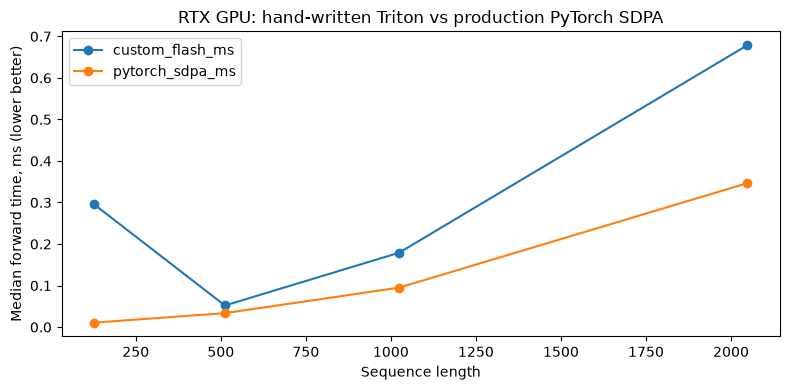

In [15]:
import triton
import triton.testing
from torch.nn.attention import sdpa_kernel, SDPBackend

def forward_benchmark(fn, warmup=20, rep=100):
    # Uses Triton's CUDA-event benchmark, synchronizes measurement.
    return float(triton.testing.do_bench(fn,warmup=warmup,rep=rep))

bench=[]
for n in (128,512,1024,2048):
    shape=(8,4,n,32)
    q,k,v=[torch.randn(shape,device=DEVICE,dtype=torch.float16) for _ in range(3)]
    custom_ms=forward_benchmark(lambda:flash_attention(q,k,v))
    sdpa_ms=forward_benchmark(lambda:F.scaled_dot_product_attention(q,k,v))
    bench.append({'seq_length':n,'custom_flash_ms':custom_ms,'pytorch_sdpa_ms':sdpa_ms,
                  'custom_over_sdpa_time_ratio':custom_ms/sdpa_ms})
bench_df=pd.DataFrame(bench)
display(bench_df)
bench_df.to_csv(OUTPUT_DIR/'flash_attention_forward_benchmark.csv',index=False)
ax=bench_df.plot(x='seq_length',y=['custom_flash_ms','pytorch_sdpa_ms'],marker='o',figsize=(8,4))
ax.set(xlabel='Sequence length',ylabel='Median forward time, ms (lower better)',title='RTX GPU: hand-written Triton vs production PyTorch SDPA')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'kernel_latency.png',dpi=180);plt.show()

### Forward + backward timing (training relevant)

Forward-only latency can be misleading. This additional microbenchmark measures both attention forward and Q/K/V gradient computation, including our custom backward. The peak figure is PyTorch allocated memory, not total physical GPU memory. Results are indicative rather than a perfectly isolated kernel study.

In [16]:
import triton.testing
fb_rows=[]
for n in (128, 512, 1024):
    for backend in ('triton_flash','torch_sdpa'):
        q,k,v=[torch.randn((4,4,n,32),device=DEVICE,dtype=torch.float16,requires_grad=True) for _ in range(3)]
        upstream=torch.randn_like(q)
        def forward_backward():
            output=(flash_attention(q,k,v) if backend=='triton_flash'
                    else F.scaled_dot_product_attention(q,k,v))
            torch.autograd.grad(output,(q,k,v),grad_outputs=upstream)
        for _ in range(5): forward_backward()
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        ms=float(triton.testing.do_bench(forward_backward,warmup=15,rep=60))
        peak_mb=torch.cuda.max_memory_allocated()/1024**2
        fb_rows.append({'seq_length':n,'backend':backend,'fwd_bwd_ms':ms,
                        'peak_allocator_mb':peak_mb})
fb_df=pd.DataFrame(fb_rows)
display(fb_df)
fb_df.to_csv(OUTPUT_DIR/'kernel_forward_backward_benchmark.csv',index=False)
print('Memory figure is allocator peak for this test, including tensors already resident; compare under same process conditions.')

,seq_length,backend,fwd_bwd_ms,peak_allocator_mb
0,128,triton_flash,0.290816,290.601562
1,128,torch_sdpa,0.862596,291.110352
2,512,triton_flash,0.897937,293.625000
3,512,torch_sdpa,0.449667,295.657227
4,1024,triton_flash,0.431564,297.656250
5,1024,torch_sdpa,0.444884,301.719727


Memory figure is allocator peak for this test, including tensors already resident; compare under same process conditions.


## 10. Save a reproducibility report, showcase a real example, and prepare submission

Submit this notebook, the two source modules, generated metrics/figures, and the method description. Replicate with 3 predetermined seeds and compare confidence intervals **without searching for a lucky test seed**. Add ablations (no multiscale stem; no engineered feature branch; no raw-stream augmentation) selected using validation. Honest results beat unsupported SOTA claims.

In [17]:
demo_i=0
example_raw=torch.from_numpy(((X_test[demo_i:demo_i+1]-full_norm[0])/full_norm[1]).astype(np.float32)).to(DEVICE)
example_feat=torch.from_numpy(full_norm[2].transform(F_test[demo_i:demo_i+1]).astype(np.float32)).to(DEVICE)
with torch.inference_mode(),amp():
    scores=final_models['triton_flash'](example_raw,example_feat).softmax(-1).float().cpu().numpy()[0]
print('ACTUAL held-out recording | Subject:',subject_test[demo_i],
      '| Ground truth:',ACTIVITIES[y_test[demo_i]])
print(pd.DataFrame({'activity':ACTIVITIES,'probability':scores}).sort_values('probability',ascending=False).to_string(index=False))

report={
 'project':'FlashHAR-X', 'dataset':'UCI HAR Using Smartphones (DOI: 10.24432/C54S4K)',
 'protocol':'Official subject-disjoint train/test; GroupShuffleSplit training-only validation; frozen final test',
 'seed':SEED,'hardware':torch.cuda.get_device_name(0),
 'torch':torch.__version__,'cuda_runtime':torch.version.cuda,
 'selected_epochs':selected_epochs, 'metrics':results,
 'note':'No model reached or beat paper SOTA unless this JSON empirically shows it; compare matching protocols.'
}
(OUTPUT_DIR/'experiment_manifest.json').write_text(json.dumps(report,indent=2,default=str))
print('Artifacts saved to:',OUTPUT_DIR.resolve())

ACTUAL held-out recording | Subject: 2 | Ground truth: STANDING
          activity  probability
          STANDING     0.988519
            LAYING     0.004203
  WALKING_UPSTAIRS     0.003110
           WALKING     0.002489
WALKING_DOWNSTAIRS     0.001373
           SITTING     0.000307
Artifacts saved to: /home/saitej/projects/FlashHAR_X/artifacts
